## Speed statistics (development)

Analyses speed statistics across development. 

Figures are saved to the project `figures/` directory and to `speed/media/`.

Import libraries:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import PROJECT_ROOT, DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
#from functions.visual_flow_behavior_plotting import *
#from functions.visual_flow_behavior_analysis import *
#from functions.brain_analysis import *
from functions.utilities import *
#from functions.feedback_models import *
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from functions.MC_plots import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd
from scipy.interpolate import interp1d
from functions.MC_utilities import *

from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
import matplotlib.cm as cm

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [2]:
from functions.MC_utilities import *
[color_y, color_m, color_o, color_low_boutID, color_med_boutID, color_high_boutID, color_cont, color_bout] = get_colors()
group_colors = [color_y, color_m, color_o]

In [3]:
print(os.getcwd()) 

<repo>/code/speed


In [4]:
# Paths from code/paths.py (project root, data, figures, local media)
path = str(PROJECT_ROOT)
path_data = str(DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("speed"))
print(path, path_data, path_figures)

<repo> <repo>/data <repo>/figures


#### Import data:

In [5]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']
#fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_31Oct24_1']
index_y = list(range(0, len(fish_ids_young)))
print(index_y)

[0, 1, 2, 3, 4]


In [6]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']
index_i = list( range(len(fish_ids_young), len(fish_ids_young)+len(fish_ids_intermediate)) )
print(index_i)

[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [7]:
fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
#fish_ids_old=['26_02May24_2','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']
index_o = list( range( len(fish_ids_young)+len(fish_ids_intermediate) , len(fish_ids_young)+len(fish_ids_intermediate)+len(fish_ids_old) ) )
print(index_o)

[16, 17, 18, 19, 20, 21]


In [8]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [9]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [10]:
index_groups = {
    '1-2 wpf': index_y,
    '3 wpf': index_i,
    '4-5 wpf': index_o
}

In [11]:
age_list = [int(fid.split('_')[0]) for fid in fish_ids]
print(age_list)

[13, 13, 13, 14, 14, 17, 18, 18, 19, 20, 20, 20, 21, 21, 21, 25, 26, 27, 28, 30, 34, 34]


Load:

In [12]:
speed_clean = pd.read_hdf(os.path.join(path_data, f"speed_clean.h5"), key='df')

In [13]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
thrust_thresholds = pd.read_hdf(os.path.join(path_data, f"thrust_thresholds.h5"), key='df')

In [15]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [16]:
onsets = pd.read_hdf(os.path.join(path_data, f"onsets.h5"), key='df')

In [17]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [18]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:03<01:14,  3.53s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:06<01:06,  3.30s/it]

...

 91%|█████████ | 20/22 [01:04<00:06,  3.20s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [01:08<00:03,  3.16s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:11<00:00,  3.23s/it]


In [19]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|          | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|▍         | 1/22 [00:03<01:09,  3.33s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|▉         | 2/22 [00:06<01:03,  3.19s/it]

...

 91%|█████████ | 20/22 [01:04<00:06,  3.35s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████▌| 21/22 [01:08<00:03,  3.45s/it]

Subsetting data of the fish 34_11Dec24_3


100%|██████████| 22/22 [01:12<00:00,  3.29s/it]


In [20]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]
onset_times_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)
    
for i in range(len(fish_ids)):  
    onset_times_list.append(t_c_list[i][onset_indices_list[i]])

100%|██████████| 22/22 [00:00<00:00, 130.17it/s]


Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_27Mar24_1
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 27_12Jun24_1
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2
Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


## start some plots to visualize data

In [21]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

14_31Oct24_1


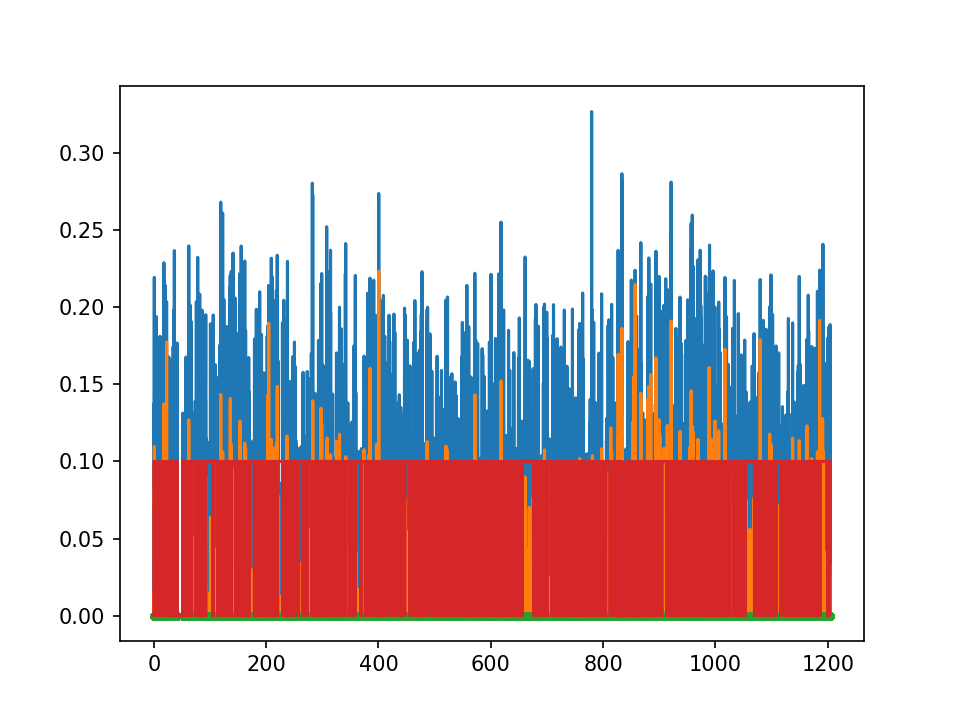

In [22]:
i=4

print(fish_ids[i])

dt=1/300
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.plot(t_c_list[i],vtail_c_list[i]/1000,'-')
#ax.plot(t_c_list[i],dangletail_c_list[i]/10,'-')
ax.plot(t_c_list[i],mean_thrust_c_list[i],'-')
#ax.axhline(thrust_thr_list[i],c='k')
ax.plot(t_c_list[i][mask_movetail_list[i]], np.zeros(np.sum(mask_movetail_list[i])),'.')

ax.plot(t_c_list[i],mask_movetail_list[i]/10,'-')

#ax.set_xlim(255,255.5)
plt.show()

In [23]:
len(mask_movetail_list[i])

361286

In [24]:
len(vfish_c_list[i])

361286

1.8880372014510913


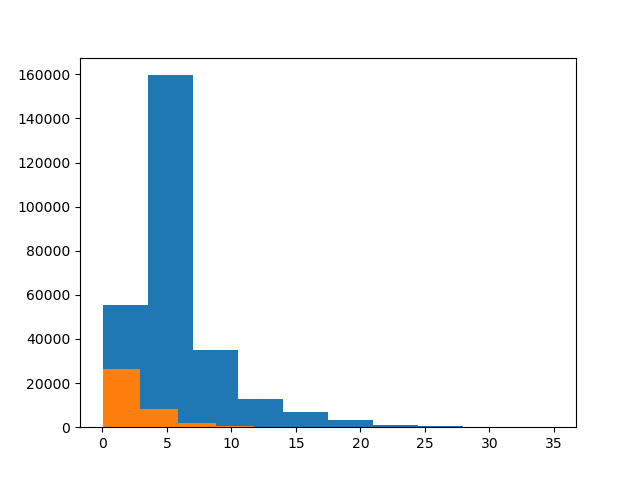

In [25]:
plt.figure()
plt.hist(vfish_c_list[i][mask_movetail_list[i]])
plt.hist(vfish_c_list[i][~mask_movetail_list[i]])
print(np.nanmedian(vfish_c_list[i][~mask_movetail_list[i]]))
plt.show()

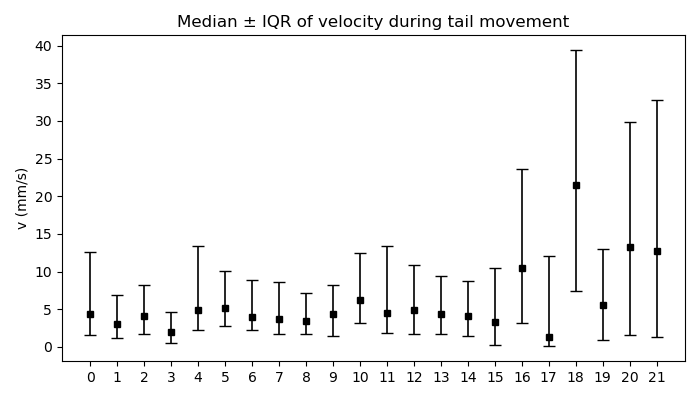

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Example data: replace with yours
# vfish_c_list = [...]
# mask_movetail_list = [...]

n_fish = len(vfish_c_list)
x_vals = np.arange(n_fish)
medians = []
iqr_lower = []
iqr_upper = []

for i in range(n_fish):
    data = vfish_c_list[i][mask_movetail_list[i]]  # tail movement
    data = data[~np.isnan(data)]  # remove NaNs

    if len(data) > 0:
        median = np.nanmedian(data)
        q1 = np.nanpercentile(data, 5) #25)
        q3 = np.nanpercentile(data, 95) #75)
        medians.append(median)
        iqr_lower.append(median - q1)
        iqr_upper.append(q3 - median)
    else:
        medians.append(np.nan)
        iqr_lower.append(0)
        iqr_upper.append(0)

# Convert to arrays
medians = np.array(medians)
iqr_lower = np.array(iqr_lower)
iqr_upper = np.array(iqr_upper)

# Plot
plt.figure(figsize=(7, 4))
plt.errorbar(x_vals, medians, yerr=[iqr_lower, iqr_upper], fmt='s', color='black',
             capsize=4, elinewidth=1.2, markersize=4, label='tail movement')

# Labels
plt.ylabel("v (mm/s)")
plt.xticks(x_vals)
#plt.ylim(0, np.nanmax(medians + iqr_upper) * 1.2)
plt.title("Median ± IQR of velocity during tail movement")
plt.tight_layout()
plt.show()

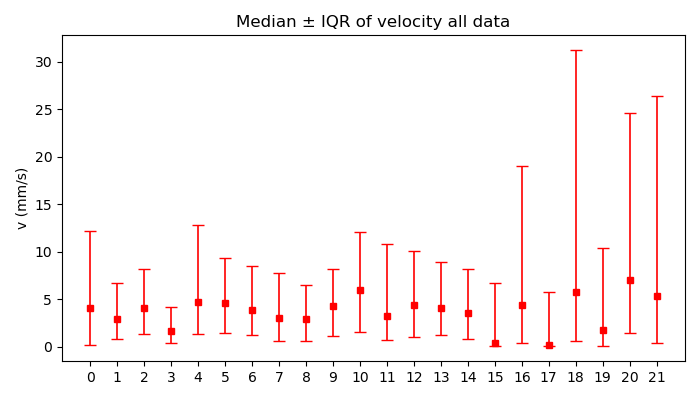

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Example data: replace with yours
# vfish_c_list = [...]
# mask_movetail_list = [...]

n_fish = len(vfish_c_list)
x_vals = np.arange(n_fish)
medians = []
iqr_lower = []
iqr_upper = []

for i in range(n_fish):
    data = vfish_c_list[i] # non-tail movement
    data = data[~np.isnan(data)]  # remove NaNs

    if len(data) > 0:
        median = np.nanmedian(data)
        q1 = np.nanpercentile(data, 5)
        q3 = np.nanpercentile(data, 95)
        medians.append(median)
        iqr_lower.append(median - q1)
        iqr_upper.append(q3 - median)
    else:
        medians.append(np.nan)
        iqr_lower.append(0)
        iqr_upper.append(0)

# Convert to arrays
medians = np.array(medians)
iqr_lower = np.array(iqr_lower)
iqr_upper = np.array(iqr_upper)

# Plot
plt.figure(figsize=(7, 4))
plt.errorbar(x_vals, medians, yerr=[iqr_lower, iqr_upper], fmt='s', color='red',
             capsize=4, elinewidth=1.2, markersize=4, label='all data')

# Labels
plt.ylabel("v (mm/s)")
plt.xticks(x_vals)
#plt.ylim(0, np.nanmax(medians + iqr_upper) * 1.2)
plt.title("Median ± IQR of velocity all data")
plt.tight_layout()
plt.show()

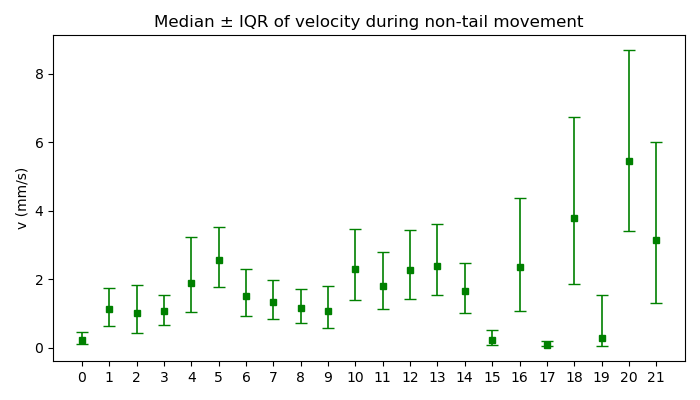

In [28]:
n_fish = len(vfish_c_list)
x_vals = np.arange(n_fish)
medians = []
iqr_lower = []
iqr_upper = []

for i in range(n_fish):
    data = vfish_c_list[i][~mask_movetail_list[i]]  # tail movement
    data = data[~np.isnan(data)]  # remove NaNs

    if len(data) > 0:
        median = np.nanmedian(data)
        q1 = np.nanpercentile(data, 25)
        q3 = np.nanpercentile(data, 75)
        medians.append(median)
        iqr_lower.append(median - q1)
        iqr_upper.append(q3 - median)
    else:
        medians.append(np.nan)
        iqr_lower.append(0)
        iqr_upper.append(0)

# Convert to arrays
medians = np.array(medians)
iqr_lower = np.array(iqr_lower)
iqr_upper = np.array(iqr_upper)

# Plot
plt.figure(figsize=(7, 4))
plt.errorbar(x_vals, medians, yerr=[iqr_lower, iqr_upper], fmt='s', color='green',
             capsize=4, elinewidth=1.2, markersize=4, label='non-tail movement')

# Labels
plt.ylabel("v (mm/s)")
plt.xticks(x_vals)
#plt.ylim(0, np.nanmax(medians + iqr_upper) * 1.2)
plt.title("Median ± IQR of velocity during non-tail movement")
plt.tight_layout()
plt.show()

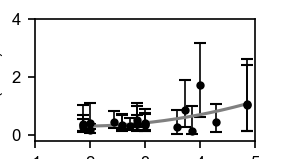

In [29]:
default()
arial()

cm_to_inch = 1 / 2.54
fig_width_cm = 4.8
fig_height_cm = 2.7

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),   dpi=150)

ages = np.array([int(fid.split('_')[0]) for fid in fish_ids])

n_fish = len(vfish_c_list)
x_vals = ages  # Use age as x-axis

medians = []
iqr_lower = []
iqr_upper = []

for i in range(n_fish):
    data = vfish_c_list[i][mask_movetail_list[i]]  # tail movement
    data = data[~np.isnan(data)]  # remove NaNs

    if len(data) > 0:
        median = np.nanmedian(data)
        q1 = np.nanpercentile(data, 5)   # 5th percentile
        q3 = np.nanpercentile(data, 95)  # 95th percentile
        medians.append(median)
        iqr_lower.append(median - q1)
        iqr_upper.append(q3 - median)
    else:
        medians.append(np.nan)
        iqr_lower.append(0)
        iqr_upper.append(0)

# Convert to arrays
medians = np.array(medians)
iqr_lower = np.array(iqr_lower)
iqr_upper = np.array(iqr_upper)

# Plot
plt.errorbar(x_vals, medians, yerr=[iqr_lower, iqr_upper], fmt='o', color='black',
             ecolor='black', elinewidth=0.8, capsize=3, markersize=3)


# Optional: trend line
valid = ~np.isnan(medians)
if np.sum(valid) >= 3:  # Need at least 3 points to fit a 2nd degree poly
    z = np.polyfit(x_vals[valid], medians[valid], 2)
    p = np.poly1d(z)
    x_fit = np.linspace(np.min(x_vals), np.max(x_vals), 200)
    plt.plot(x_fit, p(x_fit), color='gray')

plt.xlim(7, 35)
plt.xticks([7, 14, 21, 28, 35], [1, 2, 3, 4, 5])
plt.ylim(-3, 50)
plt.yticks([0, 25, 50], [0, 2, 4]) #cm/s
plt.xlabel("age (wpf)")
plt.ylabel("v (cm/s)")

fig.savefig(os.path.join(path_figures, "Fig_2b_speed_development.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_2b_speed_development.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

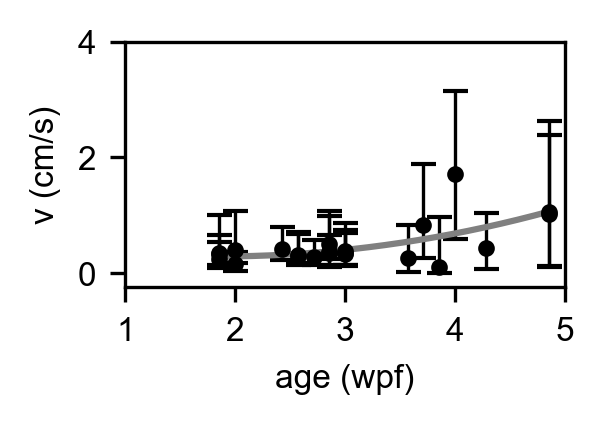

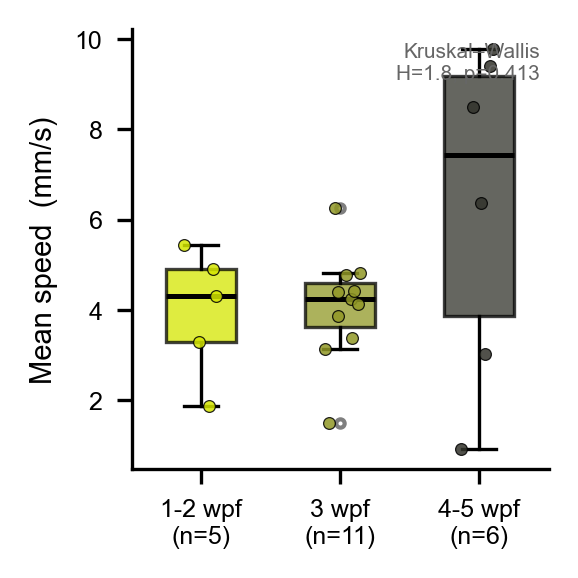

Saved → <repo>/figures/mean_speed_by_age.pdf

     Age     n   mean (mm/s)    median
--------------------------------------
 1-2 wpf     5          3.97      4.32
   3 wpf    11          4.09      4.24
 4-5 wpf     6          6.33      7.43

Kruskal–Wallis: H=1.77, p=0.4128

Pair                     raw p   corrected p    sig
--------------------------------------------------
1-2 wpf vs 3 wpf         0.9130        0.9130   n.s.
1-2 wpf vs 4-5 wpf       0.3290        0.6580   n.s.
3 wpf vs 4-5 wpf       0.2561        0.7684   n.s.


In [30]:
# =============================================================================
# Mean speed boxplot by age group
# Speed from vfish_c_list (mm/s, all frames per fish)
# One value per fish = mean across all finite frames
# =============================================================================
%matplotlib inline

from scipy.stats import kruskal, mannwhitneyu
from itertools import combinations

CM        = 1 / 2.54
DPI       = 300
LABELSIZE = 7
TICK_SIZE = 6

AGE_GROUP_ORDER = ['1-2 wpf', '3 wpf', '4-5 wpf']
GROUP_INDICES   = [index_y, index_i, index_o]
BOX_COLORS      = dict(zip(AGE_GROUP_ORDER, group_colors))

# ── Per-fish mean speed ───────────────────────────────────────────────────────
speed_by_group = {ag: [] for ag in AGE_GROUP_ORDER}
for ag, idx_list in zip(AGE_GROUP_ORDER, GROUP_INDICES):
    for i in idx_list:
        v = np.asarray(vfish_c_list[i], dtype=float)
        v = v[np.isfinite(v)]
        if len(v) > 0:
            speed_by_group[ag].append(float(np.nanmean(v)))

# ── Statistics ────────────────────────────────────────────────────────────────
groups_data = [speed_by_group[ag] for ag in AGE_GROUP_ORDER]
H, p_kw = kruskal(*[g for g in groups_data if len(g) > 0])

pairs = list(combinations(AGE_GROUP_ORDER, 2))
raw_p = []
for ag1, ag2 in pairs:
    g1, g2 = speed_by_group[ag1], speed_by_group[ag2]
    _, p = mannwhitneyu(g1, g2, alternative='two-sided') if (g1 and g2) else (None, np.nan)
    raw_p.append(p)

# Holm–Bonferroni correction
order     = np.argsort(raw_p)
corrected = [np.nan] * len(raw_p)
n_p       = len(raw_p)
for rank, idx in enumerate(order):
    corrected[idx] = min(float(raw_p[idx]) * (n_p - rank), 1.0)

def _sig(p):
    if np.isnan(p): return 'n.s.'
    if p < 0.001:   return '***'
    if p < 0.01:    return '**'
    if p < 0.05:    return '*'
    return 'n.s.'

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5 * CM, 5 * CM), dpi=DPI)

positions = list(range(len(AGE_GROUP_ORDER)))
box_data  = [speed_by_group[ag] for ag in AGE_GROUP_ORDER]

bp = ax.boxplot(box_data, positions=positions, widths=0.5,
                patch_artist=True, notch=False,
                medianprops=dict(color='k', lw=1.2),
                whiskerprops=dict(color='k', lw=0.8),
                capprops=dict(color='k', lw=0.8),
                flierprops=dict(marker='o', markersize=2, color='k', alpha=0.5, lw=0))

for patch, ag in zip(bp['boxes'], AGE_GROUP_ORDER):
    patch.set_facecolor(BOX_COLORS[ag])
    patch.set_alpha(0.75)
    patch.set_edgecolor('k')
    patch.set_linewidth(0.8)

# Jittered individual fish dots
rng = np.random.default_rng(42)
for i, ag in enumerate(AGE_GROUP_ORDER):
    vals   = np.array(speed_by_group[ag])
    jitter = rng.uniform(-0.15, 0.15, size=len(vals))
    ax.scatter(i + jitter, vals, s=8, color=BOX_COLORS[ag],
               edgecolors='k', linewidths=0.3, zorder=3, alpha=0.85)

# Significance bars (significant pairs only)
y_vals = [v for g in box_data for v in g]
y_top  = max(y_vals) * 1.05
y_step = (max(y_vals) - min(y_vals)) * 0.10
for k, (ag1, ag2) in enumerate(pairs):
    lbl = _sig(corrected[k])
    if lbl == 'n.s.':
        continue
    i1 = AGE_GROUP_ORDER.index(ag1)
    i2 = AGE_GROUP_ORDER.index(ag2)
    y  = y_top + k * y_step
    ax.plot([i1, i1, i2, i2], [y, y + y_step * 0.3, y + y_step * 0.3, y],
            lw=0.8, color='k')
    ax.text((i1 + i2) / 2, y + y_step * 0.35, lbl,
            ha='center', va='bottom', fontsize=TICK_SIZE)

ax.set_xticks(positions)
ax.set_xticklabels([f'{ag}\n(n={len(speed_by_group[ag])})' for ag in AGE_GROUP_ORDER],
                   fontsize=TICK_SIZE)
ax.set_ylabel('Mean speed  (mm/s)', fontsize=LABELSIZE)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(labelsize=TICK_SIZE)
ax.text(0.98, 0.97,
        f'Kruskal–Wallis\nH={H:.1f}, p={p_kw:.3f}',
        transform=ax.transAxes, ha='right', va='top',
        fontsize=TICK_SIZE - 1, color='0.4')

plt.tight_layout()
fig.savefig(os.path.join(path_figures, 'mean_speed_by_age.pdf'), dpi=DPI, bbox_inches='tight')
fig.savefig(os.path.join(path_media,   'mean_speed_by_age.pdf'), dpi=DPI, bbox_inches='tight')
fig.savefig(os.path.join(path_media,   'mean_speed_by_age.png'), dpi=DPI, bbox_inches='tight')
plt.show()
print(f"Saved → {os.path.join(path_figures, 'mean_speed_by_age.pdf')}")

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"\n{'Age':>8}  {'n':>4}  {'mean (mm/s)':>12}  {'median':>8}")
print('-' * 38)
for ag in AGE_GROUP_ORDER:
    vals = np.array(speed_by_group[ag])
    print(f"{ag:>8}  {len(vals):>4}  {np.mean(vals):>12.2f}  {np.median(vals):>8.2f}")
print(f"\nKruskal–Wallis: H={H:.2f}, p={p_kw:.4f}")
print(f"\n{'Pair':<20}  {'raw p':>8}  {'corrected p':>12}  {'sig':>5}")
print('-' * 50)
for k, (ag1, ag2) in enumerate(pairs):
    print(f"{ag1} vs {ag2:<10}  {raw_p[k]:>8.4f}  {corrected[k]:>12.4f}  {_sig(corrected[k]):>5}")